# Question 1: Image Preprocessing for Inference (PyTorch)
### Write a function to load an image and preprocess it for inference.

In [1]:
from PIL import Image
import torch
from torchvision import transforms

def preprocess_image(image_path):
    image=Image.open(image_path).convert("RGB")
    transform=transforms.Compose([transforms.Resize((224, 224)),transforms.ToTensor()])
    image_tensor = transform(image).unsqueeze(0)
    return image_tensor

image_tensor=preprocess_image("images/sample.jpg")
print("Image shape:", image_tensor.shape)

Image shape: torch.Size([1, 3, 224, 224])


# Question 2: Predict on New Image with a Trained Model
### Perform prediction and get the class label.

In [2]:
import torch
from torchvision import models, transforms
from PIL import Image

weights=models.ResNet18_Weights.DEFAULT
model=models.resnet18(weights=weights)
model.eval()

image=Image.open("images/new_image.jpg").convert("RGB")
preprocess=weights.transforms()
image_tensor=preprocess(image).unsqueeze(0)

with torch.no_grad():
    prediction=model(image_tensor)
    predicted_index=prediction.argmax(dim=1).item()

class_label=weights.meta["categories"][predicted_index]
print("Predicted class:", class_label)

Predicted class: tiger


# Question 3: Build a CNN to classify CIFAR-10 images (PyTorch)
### Create a CNN model that classifies images from the CIFAR-10 dataset with accuracy above 60%.

In [3]:
# Load and prepare the CIFAR-10 dataset for training and testing
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform=transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5),(0.5, 0.5, 0.5))])

train_dataset=datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)
test_dataset=datasets.CIFAR10(root="./data",train=False,download=True,transform=transform)

train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


In [4]:
# Build and initialize the CNN model for CIFAR-10 image classification
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features=nn.Sequential(nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                                    nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                                    nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))

        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(128 *4 *4,256),nn.ReLU(),
                                      nn.Dropout(0.3),nn.Linear(256,10))

    def forward(self, x):
        x=self.features(x)
        return self.classifier(x)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=CNN().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

print("Model created successfully!")
print("Device:", device)

Model created successfully!
Device: cpu


In [5]:
# Train CNN with progress, loss, and accuracy
from tqdm.auto import tqdm

for epoch in range(10):
    model.train()
    loss_sum,correct,total=0,0,0

    for images,labels in tqdm(train_loader,desc=f"Epoch {epoch+1}/10",ncols=80):
        images,labels=images.to(device),labels.to(device)
        optimizer.zero_grad()
        outputs=model(images)
        loss=criterion(outputs,labels)
        loss.backward()
        optimizer.step()

        loss_sum+=loss.item()
        correct+=(outputs.argmax(1)==labels).sum().item()
        total+=labels.size(0)

    print(f"Loss: {loss_sum/len(train_loader):.4f} | Accuracy: {100*correct/total:.2f}%")

Epoch 1/10:   0%|                                       | 0/782 [00:00<?, ?it/s]

Loss: 1.4172 | Accuracy: 48.58%


Epoch 2/10:   0%|                                       | 0/782 [00:00<?, ?it/s]

Loss: 1.0067 | Accuracy: 64.20%


Epoch 3/10:   0%|                                       | 0/782 [00:00<?, ?it/s]

Loss: 0.8275 | Accuracy: 70.73%


... (10 outputs left out)

Epoch 9/10:   0%|                                       | 0/782 [00:00<?, ?it/s]

Loss: 0.3553 | Accuracy: 87.19%


Epoch 10/10:   0%|                                      | 0/782 [00:00<?, ?it/s]

Loss: 0.3130 | Accuracy: 88.84%


In [6]:
# Evaluate the CNN model on the test dataset
model.eval()
correct=total=0

with torch.no_grad():
    for images,labels in test_loader:
        images,labels=images.to(device),labels.to(device)
        outputs=model(images)
        correct+=(outputs.argmax(1)==labels).sum().item()
        total+=labels.size(0)

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Accuracy: 75.98%


# Question 4: Identify Overfitting from Training Logs and Solve It
### You notice the training accuracy increases but validation accuracy stagnates. Modify the model using dropout and early stopping. (use mnist dataset)


In [7]:
# Load and prepare the MNIST dataset
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

transform=transforms.ToTensor()
dataset=datasets.MNIST("./data",train=True,download=True,transform=transform)
test_dataset=datasets.MNIST("./data",train=False,download=True,transform=transform)

train_dataset,val_dataset=random_split(dataset,[55000,5000])

train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=64)
test_loader=DataLoader(test_dataset,batch_size=64)

print("Training:", len(train_dataset), "| Validation:", len(val_dataset), "| Test:", len(test_dataset))

Training: 55000 | Validation: 5000 | Test: 10000


In [8]:
# Create a CNN model with Dropout
class MNISTNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(nn.Flatten(),nn.Linear(28*28,256),nn.ReLU(),nn.Dropout(0.3),nn.Linear(256,10))

    def forward(self, x):
        return self.model(x)

model= MNISTNet().to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)

print("Model created successfully")

Model created successfully


In [9]:
# Train the model with Early Stopping
from tqdm.auto import tqdm

best_val_loss=float("inf")
patience, wait=3,0
best_state=None

for epoch in range(10):
    model.train()
    train_correct=train_total=0

    for images,labels in tqdm(train_loader,desc=f"Epoch {epoch+1}/10",ncols=80):
        images,labels=images.to(device),labels.to(device)
        optimizer.zero_grad()
        outputs=model(images)
        loss=criterion(outputs,labels)
        loss.backward()
        optimizer.step()

        train_correct+=(outputs.argmax(1)==labels).sum().item()
        train_total+=labels.size(0)

    model.eval()
    val_loss=0
    val_correct=val_total=0

    with torch.no_grad():
        for images,labels in val_loader:
            images,labels=images.to(device),labels.to(device)
            outputs=model(images)
            val_loss+=criterion(outputs,labels).item()
            val_correct+=(outputs.argmax(1)==labels).sum().item()
            val_total+=labels.size(0)

    val_loss/=len(val_loader)
    train_acc=100*train_correct/train_total
    val_acc=100*val_correct/val_total

    print(f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}% | Val Loss: {val_loss:.4f}")

    if val_loss<best_val_loss:
        best_val_loss=val_loss
        best_state={k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
        wait=0
    else:
        wait+=1
        if wait>=patience:
            print("Early stopping triggered.")
            break

if best_state is not None:
    model.load_state_dict(best_state)

Epoch 1/10:   0%|                                       | 0/860 [00:00<?, ?it/s]

Train Acc: 90.16% | Val Acc: 94.34% | Val Loss: 0.1936


Epoch 2/10:   0%|                                       | 0/860 [00:00<?, ?it/s]

Train Acc: 95.22% | Val Acc: 96.26% | Val Loss: 0.1255


Epoch 3/10:   0%|                                       | 0/860 [00:00<?, ?it/s]

Train Acc: 96.51% | Val Acc: 96.78% | Val Loss: 0.1049


... (10 outputs left out)

Epoch 9/10:   0%|                                       | 0/860 [00:00<?, ?it/s]

Train Acc: 98.53% | Val Acc: 98.12% | Val Loss: 0.0688


Epoch 10/10:   0%|                                      | 0/860 [00:00<?, ?it/s]

Train Acc: 98.62% | Val Acc: 97.94% | Val Loss: 0.0702


In [10]:
# Evaluate the model on test data
model.eval()
correct=total=0

with torch.no_grad():
    for images,labels in test_loader:
        images,labels=images.to(device),labels.to(device)
        outputs=model(images)
        correct+=(outputs.argmax(1)==labels).sum().item()
        total+=labels.size(0)

print(f"Test Accuracy: {100 *correct/total:.2f}%")

Test Accuracy: 98.12%


# Question 5: Transfer Learning with Pretrained VGG16 (Cats vs Dogs)
### Use VGG16 for binary classification with fine-tuning

In [11]:
# Load and prepare the Cats vs Dogs dataset
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

dataset_path="cats_dogs/PetImages"

train_dataset=image_dataset_from_directory(dataset_path,validation_split=0.2,subset="training",seed=42,
                                           image_size=(128, 128),batch_size=32,label_mode="binary")

val_dataset=image_dataset_from_directory(dataset_path,validation_split=0.2,subset="validation",seed=42,
                                         image_size=(128, 128),batch_size=32,label_mode="binary")

print("Training and validation datasets are ready.")

C:\Anaconda3\envs\aidl\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.
Training and validation datasets are ready.


In [12]:
# Create the VGG16 transfer learning model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models

base_model=VGG16(weights="imagenet",include_top=False,input_shape=(128,128,3))
base_model.trainable=False

model=models.Sequential([layers.Input(shape=(128,128,3)),layers.Lambda(preprocess_input),base_model,layers.GlobalAveragePooling2D(),
                         layers.Dense(128,activation="relu"),layers.Dropout(0.3),layers.Dense(1,activation="sigmoid")])

model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [13]:
# Train the VGG16 model 
history=model.fit(train_dataset,validation_data=val_dataset,epochs=5)

Epoch 1/5


C:\Anaconda3\envs\aidl\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


625/625 ━━━━━━━━━━━━━━━━━━━━ 4413s 7s/step - accuracy: 0.9318 - loss: 0.2992 - val_accuracy: 0.9634 - val_loss: 0.0935
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4981s 8s/step - accuracy: 0.9630 - loss: 0.1001 - val_accuracy: 0.9616 - val_loss: 0.0895
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5519s 9s/step - accuracy: 0.9703 - loss: 0.0805 - val_accuracy: 0.9640 - val_loss: 0.0910
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4159s 7s/step - accuracy: 0.9739 - loss: 0.0694 - val_accuracy: 0.9658 - val_loss: 0.0927
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4256s 7s/step - accuracy: 0.9783 - loss: 0.0594 - val_accuracy: 0.9620 - val_loss: 0.1005


In [14]:
# Evaluate the trained VGG16 model
loss,accuracy=model.evaluate(val_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

157/157 ━━━━━━━━━━━━━━━━━━━━ 958s 6s/step - accuracy: 0.9620 - loss: 0.1005
Validation Loss: 0.10054395347833633
Validation Accuracy: 0.9619923830032349


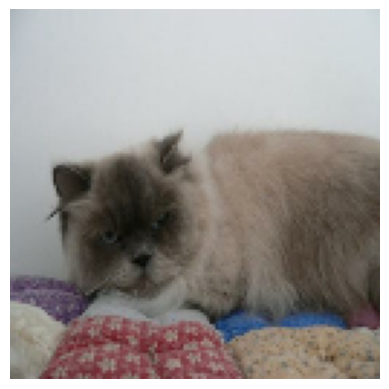

Actual Class: Cat
Predicted Class: Cat
Prediction Score: 0.0


In [15]:
# Predict one image using the trained VGG16 model
import matplotlib.pyplot as plt

for images,labels in val_dataset.take(1):
    prediction=model.predict(images,verbose=0)

    actual_class=int(labels[0][0])
    predicted_class=int(prediction[0][0]>=0.5)
    confidence=float(prediction[0][0])

    class_names=val_dataset.class_names

    plt.imshow(images[0].numpy().astype("uint8"))
    plt.axis("off")
    plt.show()

    print("Actual Class:", class_names[actual_class])
    print("Predicted Class:", class_names[predicted_class])
    print("Prediction Score:", round(confidence,4))

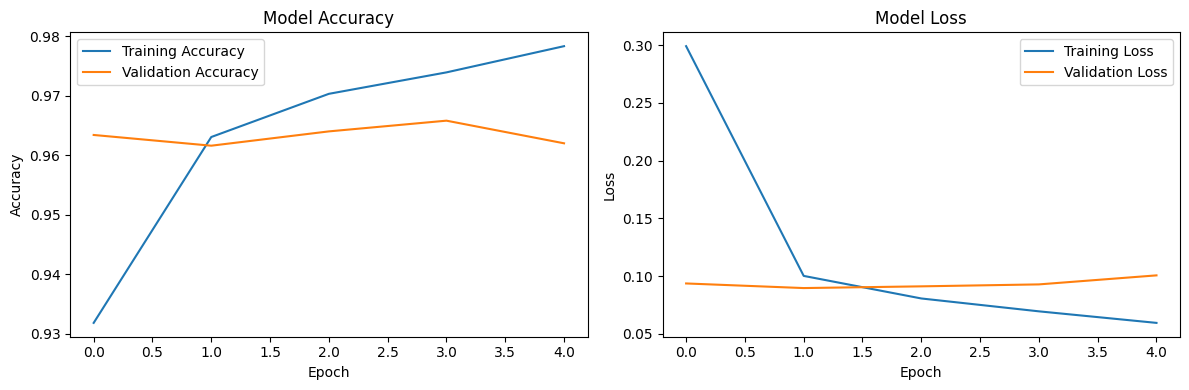

In [16]:
# Visualize training and validation performance
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1,2,1)
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()